# Responsible and Safe AI (AIML4001) by Siddhraj Thakor 23AIML070

### Installing and importing libraries
SHAP and LIME are not installed in Colab by default, so they are installed first.

In [1]:
!pip install -q shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("ignore")

### Loading the dataset
The values in the raw file are codes, so they are mapped to readable words first.

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"

cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount",
        "savings_status", "employment", "installment_commitment", "personal_status",
        "other_parties", "residence_since", "property_magnitude", "age",
        "other_payment_plans", "housing", "existing_credits", "job", "num_dependents",
        "own_telephone", "foreign_worker", "class"]

labels = {
    "checking_status": {"A11": "<0", "A12": "0<=X<200", "A13": ">=200", "A14": "no checking"},
    "credit_history": {"A30": "no credits/all paid", "A31": "all paid", "A32": "existing paid",
                       "A33": "delayed previously", "A34": "critical/other existing credit"},
    "purpose": {"A40": "new car", "A41": "used car", "A42": "furniture/equipment",
                "A43": "radio/tv", "A44": "domestic appliance", "A45": "repairs",
                "A46": "education", "A47": "vacation", "A48": "retraining",
                "A49": "business", "A410": "other"},
    "savings_status": {"A61": "<100", "A62": "100<=X<500", "A63": "500<=X<1000",
                       "A64": ">=1000", "A65": "no known savings"},
    "employment": {"A71": "unemployed", "A72": "<1", "A73": "1<=X<4", "A74": "4<=X<7", "A75": ">=7"},
    "personal_status": {"A91": "male div/sep", "A92": "female div/dep/mar", "A93": "male single",
                        "A94": "male mar/wid", "A95": "female single"},
    "other_parties": {"A101": "none", "A102": "co applicant", "A103": "guarantor"},
    "property_magnitude": {"A121": "real estate", "A122": "life insurance", "A123": "car",
                           "A124": "no known property"},
    "other_payment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unemp/unskilled non res", "A172": "unskilled resident",
            "A173": "skilled", "A174": "high qualif/self emp/mgmt"},
    "own_telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
    "class": {1: "good", 2: "bad"},
}

data = pd.read_csv(url, header=None, names=cols)
for c in labels:
    data[c] = data[c].map(labels[c])
data.to_csv("german_credit.csv", index=False)

### Task 1: Encode the data and split it
The target is 1 for bad and 0 for good. OrdinalEncoder keeps every attribute as one feature. The split is 80:20 and stratified.

In [4]:
df = pd.read_csv("german_credit.csv")
y = (df["class"] == "bad").astype(int)
X_raw = df.drop("class", axis=1)
cat_cols = X_raw.select_dtypes(exclude="number").columns.tolist()
features = X_raw.columns.tolist()

enc = OrdinalEncoder()
X = X_raw.copy()
X[cat_cols] = enc.fit_transform(X_raw[cat_cols])
X = X.astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Dataset : German Credit (UCI Statlog), shape =", df.shape)
print("Train :", X_train.shape, " Test :", X_test.shape)

Dataset : German Credit (UCI Statlog), shape = (1000, 21)
Train : (800, 20)  Test : (200, 20)


### Task 2: Random Forest model
Random Forest with 200 trees and depth 8. Accuracy is taken at a 0.5 threshold on P(bad), and ROC-AUC is found from the probabilities.

In [5]:
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)

p_bad = rf.predict_proba(X_test)[:, 1]
pred = (p_bad >= 0.5).astype(int)
acc = accuracy_score(y_test, pred)
auc = roc_auc_score(y_test, p_bad)

print("\nModel : RandomForest (200 trees, depth 8)")
print(f"Test accuracy : {acc:.2f}   ROC-AUC : {auc:.2f}")


Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.77   ROC-AUC : 0.83


### Task 3: SHAP global feature importance
The mean of the absolute SHAP values for the class "bad" is used to rank the features. The summary plot is saved as `shap_summary.png`.


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE                   MEAN|SHAP|
---------------------------------------------
1     checking_status           0.092
2     duration                  0.042
3     credit_amount             0.027
4     savings_status            0.027
5     purpose                   0.025
---------------------------------------------


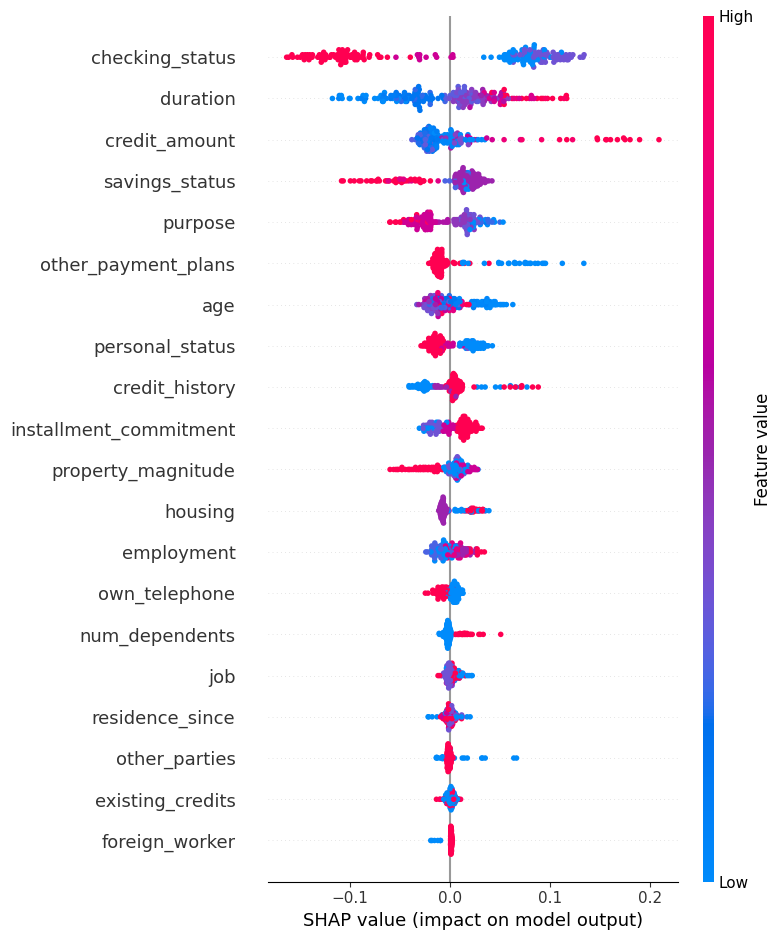

Plot saved : shap_summary.png


In [6]:
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]
base = float(np.atleast_1d(explainer.expected_value)[-1])

mean_shap = np.abs(sv).mean(axis=0)
order = np.argsort(-mean_shap)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print(f"{'RANK':<6}{'FEATURE':<26}{'MEAN|SHAP|'}")
print("-" * 45)
for n, i in enumerate(order[:5], 1):
    print(f"{n:<6}{features[i]:<26}{mean_shap[i]:.3f}")
print("-" * 45)

plt.figure()
shap.summary_plot(sv, X_test, feature_names=features, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_summary.png")

### Task 4: SHAP explanation of a rejected applicant
The first test applicant predicted as bad is selected. The waterfall plot is saved as `shap_waterfall.png`. The three features with the biggest positive SHAP values are the top 3 reasons.


Applicant (test index 570) : P(bad) = 0.57 -> REJECTED


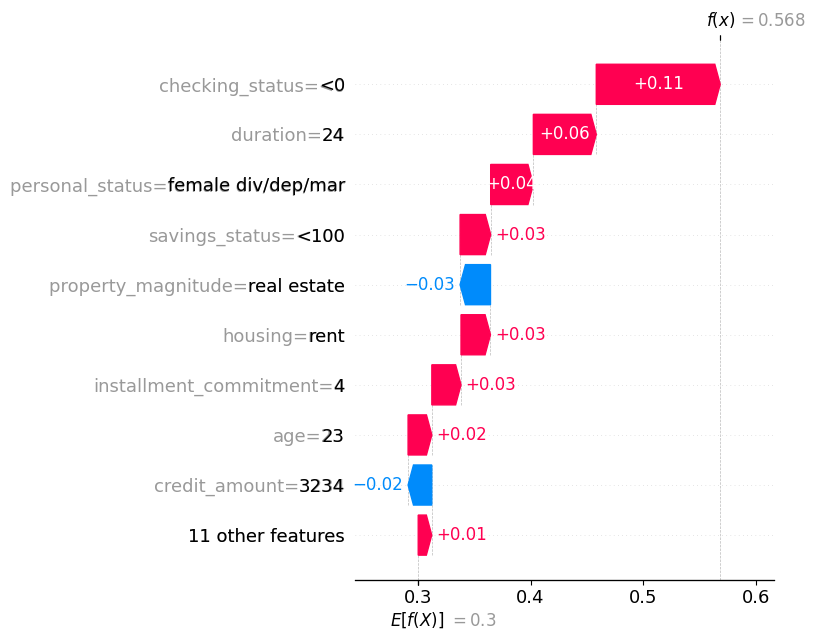

In [7]:
rejected = np.where(pred == 1)[0]
k = rejected[0]
idx = X_test.index[k]
row = X_raw.loc[idx]
names = [f"{c}={row[c]}" for c in features]

print(f"\nApplicant (test index {idx}) : P(bad) = {p_bad[k]:.2f} -> REJECTED")

ex = shap.Explanation(values=sv[k], base_values=base, data=None, feature_names=names)
plt.figure()
shap.plots.waterfall(ex, max_display=10, show=False)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

shap_top = np.argsort(-sv[k])[:3]

### Task 5: LIME explanation and comparison
The same applicant is explained with LIME using 5 features. The table shows SHAP and LIME side by side and the last line shows how many of the top 3 are common. The LIME plot is saved as `lime_explanation.png`.

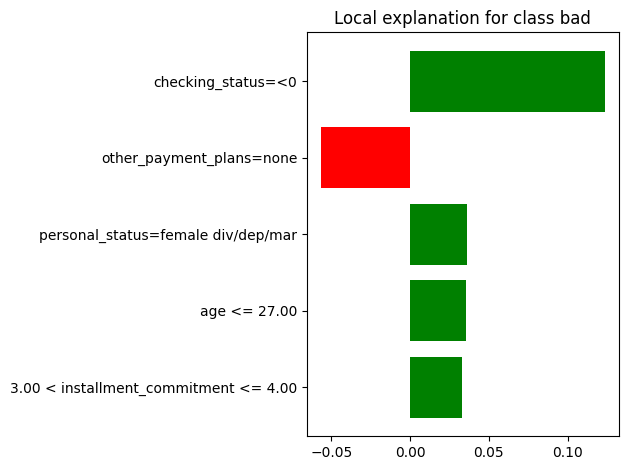


SHAP (top 3)                              LIME (top 5)
--------------------------------------------------------------------------------
checking_status=<0 +0.11                  checking_status=<0 +0.12
duration=24 +0.06                         other_payment_plans=none -0.06
personal_status=female div/dep/mar +0.04  personal_status=female div/dep/mar +0.04
                                          age <= 27.00 +0.04
                                          3.00 < installment_commitment <= 4.00 +0.03
--------------------------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 2 / 3


In [8]:
cat_idx = [features.index(c) for c in cat_cols]
cat_names = {i: list(enc.categories_[j]) for j, i in enumerate(cat_idx)}

lime_ex = LimeTabularExplainer(
    X_train.values,
    feature_names=features,
    class_names=["good", "bad"],
    categorical_features=cat_idx,
    categorical_names=cat_names,
    mode="classification",
    random_state=42)

predict_fn = lambda a: rf.predict_proba(pd.DataFrame(a, columns=features))
lime_out = lime_ex.explain_instance(X_test.iloc[k].values, predict_fn,
                                    num_features=5, labels=(1,))
lime_list = lime_out.as_list(label=1)
lime_idx = [i for i, w in lime_out.as_map()[1]]

fig = lime_out.as_pyplot_figure(label=1)
plt.tight_layout()
fig.savefig("lime_explanation.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n{'SHAP (top 3)':<42}LIME (top 5)")
print("-" * 80)
for n in range(5):
    left = ""
    if n < 3:
        j = shap_top[n]
        left = f"{names[j]} {sv[k][j]:+.2f}"
    print(f"{left:<42}{lime_list[n][0]} {lime_list[n][1]:+.2f}")
print("-" * 80)

common = set(shap_top) & set(lime_idx[:3])
print(f"Top-3 agreement (SHAP vs LIME) : {len(common)} / 3")

### Task 6: Rejection message and sensitive attribute check
The message is made from the top positive reasons that are not sensitive. Age, personal_status and foreign_worker are checked against the SHAP and LIME reasons.

In [9]:
sensitive = ["age", "personal_status", "foreign_worker"]
used = [features[i] for i in list(shap_top) + lime_idx]
found = [f for f in sensitive if f in used]
if found:
    print("Sensitive attributes in reasons :", ", ".join(found), "-> REVIEW")
else:
    print("Sensitive attributes in reasons : none -> OK")

def reason_text(name, value):
    if name == "checking_status":
        if value == "<0":
            return "your current account balance is negative"
        if value == "no checking":
            return "no checking account is on record for you"
        return "your current account balance is low"
    if name == "duration":
        return f"the requested duration ({value} months) is long"
    if name == "credit_amount":
        return f"the requested loan amount ({value}) is high"
    if name == "savings_status":
        return f"your savings balance ({value}) is limited"
    if name == "credit_history":
        return f"your earlier credit history ({value}) raises concern"
    if name == "purpose":
        return f"the loan purpose ({value}) carries higher risk"
    if name == "employment":
        return f"your present employment period ({value} years) is short"
    return f"your {name.replace('_', ' ')} ({value}) raised the risk"

positive = [i for i in np.argsort(-sv[k]) if sv[k][i] > 0]
legit = [i for i in positive if features[i] not in sensitive][:2]
reasons = [reason_text(features[i], row[features[i]]) for i in legit]
message = "Your EMI request was not approved mainly because " + " and ".join(reasons) + "."
print("Message (legitimate reasons only):")
print('"' + message + '"')

Sensitive attributes in reasons : age, personal_status -> REVIEW
Message (legitimate reasons only):
"Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long."


## Result Summary

| Item | Value |
|---|---|
| Train / Test split | 800 / 200 |
| Test accuracy | 0.77 |
| ROC-AUC | 0.83 |
| Top 5 features | checking_status, duration, credit_amount, savings_status, purpose |
| Selected applicant | test index 570, P(bad) = 0.57 (rejected) |
| SHAP and LIME top-3 agreement | 2 / 3 |
| Sensitive attributes in reasons | age, personal_status |